In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add repo root to sys.path if this notebook is under examples/
try:
    CWD = Path.cwd()
    for cand in [CWD, *CWD.parents]:
        if (cand / 'src').exists():
            sys.path.insert(0, str(cand))
            break
except Exception:
    pass

# Try repo-local imports first, then installed package
try:
    from src.resonator import Resonator
    from src.fit_methods.dcm import DCM
    from src.fit_methods.reflection import ReflectionMode
except Exception:
    try:
        from scresonators.resonator import Resonator
        from scresonators.fit_methods.dcm import DCM
        from scresonators.fit_methods.reflection import ReflectionMode
    except Exception:
        try:
            from fit_resonator.resonator import Resonator
            from fit_resonator.fit_methods.dcm import DCM
            from fit_resonator.fit_methods.reflection import ReflectionMode
        except Exception as e:
            raise RuntimeError("Could not import scresonators. Run from repo root or install scresonators (or scresonators-fit).") from e


## Configure Inputs
Edit paths and options below to match your data. For the repo example files, the defaults work.


In [2]:
# Paths to your data
freq_path = Path('frequencies.npy')  # .npy or .csv
s21_path  = Path('S21_RAW.npy')  # .npy or .csv

# Choose format of S21 if not complex npy
# Options: 'complex_npy', 'reim_csv', 'magphase_deg_csv'
s21_format = 'complex_npy'

# Frequency units of your input file; converted to GHz internally
# Options: 'GHz', 'Hz', 'MHz', 'kHz'
freq_units = 'GHz'

# Choose fitting method: 'dcm' for hanger (S21), 'reflection' for S11
method = 'dcm'

# Preprocessing: set False to skip electrical delay removal
remove_electrical_delay = True

## Load Data Helpers
Utilities to load arrays and parse S21 into complex form.

In [3]:
def load_array(path: Path) -> np.ndarray:
    path = Path(path)
    if path.suffix.lower() == '.npy':
        return np.load(path)
    # CSV/TXT fallback
    return np.genfromtxt(path, delimiter=',', dtype=float)

def parse_s21(data: np.ndarray, fmt: str) -> np.ndarray:
    fmt = fmt.lower()
    if fmt == 'complex_npy':
        if not np.iscomplexobj(data):
            raise ValueError('Expected complex dtype in npy for complex_npy format.')
        return data.astype(np.complex128)
    if fmt == 'reim_csv':
        if data.ndim == 1 or data.shape[1] < 2:
            raise ValueError('reim_csv expects 2 columns: re,im')
        return (data[:, 0] + 1j * data[:, 1]).astype(np.complex128)
    if fmt == 'magphase_deg_csv':
        if data.ndim == 1 or data.shape[1] < 2:
            raise ValueError('magphase_deg_csv expects 2 columns: mag,phase_deg')
        mag = data[:, 0]
        ph = np.deg2rad(data[:, 1])
        return (mag * np.exp(1j * ph)).astype(np.complex128)
    raise ValueError(f'Unknown s21-format: {fmt}')

def convert_freq_to_ghz(f: np.ndarray, units: str) -> np.ndarray:
    units = units.lower()
    scale = {'hz': 1e-9, 'khz': 1e-6, 'mhz': 1e-3, 'ghz': 1.0}
    if units not in scale:
        raise ValueError(f'Unsupported units: {units}')
    f_ghz = f * scale[units]
    return f_ghz.squeeze()


## Load and Inspect Data
Loads data using the settings above and shows basic info.


In [4]:
# Load frequency and S21
freqs_raw = load_array(freq_path).astype(float)
s21_raw = load_array(s21_path)

# Convert frequencies to GHz
freqs = convert_freq_to_ghz(freqs_raw, freq_units)

# Parse S21 according to selected format or auto-detect if possible
if s21_format == 'complex_npy' and s21_raw.ndim > 1:
    # If user selected complex_npy but provided 2-column CSV, try re,im as a convenience
    s21 = parse_s21(s21_raw, 'reim_csv')
else:
    s21 = parse_s21(s21_raw, s21_format)

print(f'freqs shape: {freqs.shape}, dtype: {freqs.dtype}')
print(f's21 shape:   {s21.shape}, dtype: {s21.dtype}, complex: {np.iscomplexobj(s21)}')
assert freqs.shape[0] == s21.shape[0], 'Frequency and S21 lengths must match'


freqs shape: (5001,), dtype: float64
s21 shape:   (5001,), dtype: complex128, complex: True


## Run Fit
Creates a `Resonator`, selects the fitting strategy, runs the fit, and prints parameters.

In [5]:
res = Resonator()
res.load_data(fdata=freqs, sdata=s21)

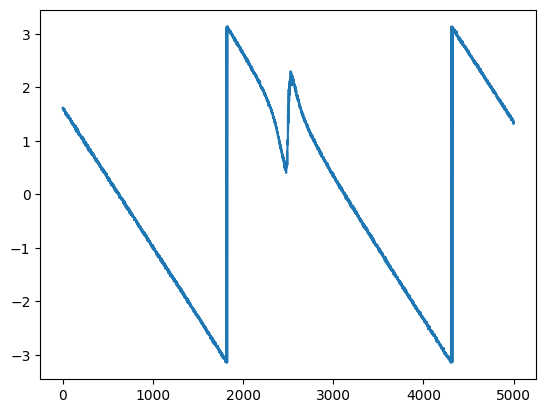

In [6]:
plt.plot(np.angle(res.sdata))

In [ ]:

if method.lower() == 'dcm':
    res.set_fitting_strategy(strategy=DCM())
elif method.lower() == 'reflection':
    res.set_fitting_strategy(strategy=ReflectionMode())
else:
    raise ValueError('method must be "dcm" or "reflection"')

res.fitter.databg = False
res.fitter.preprocess = True
res.fitter.remove_elec_delay = True
res.fitter.preprocess_circle = True

params = res.fit(verbose=True)

def pval(name):  
    if name not in params:
        return None, None
    v = params[name].value
    se = params[name].stderr
    return v, se

print('Fit parameters:')
for key in ['f0', 'Q', 'Qc', 'Qi', 'phi']:
    v, se = pval(key)
    if v is None:
        continue
    se_str = f' ± {se:.3g}' if se is not None else ''
    print(f'  {key}: {v:.9g}{se_str}')


Q_guess: 7565.525683060109
phi (preprocessing): 0.05201583736276483
Q_guess: 7565.525683060109
[[Model]]
    Model(func)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 47
    # data points      = 10002
    # variables        = 4
    chi-square         = 7147.37856
    reduced chi-square = 0.71488083
    Akaike info crit   = -3353.06626
    Bayesian info crit = -3324.22410
    R-squared          = np.complex128(-9.933064882219414-2.5556676532864455j)
[[Variables]]
    Q:    1041.65462 +/- 33.3350386 (3.20%) (init = 7565.526)
    Qc:   753.742887 +/- 18.3400874 (2.43%) (init = 3855.066)
    f0:   6.9223e+09 +/- 106348.031 (0.00%) (init = 6.922456e+09)
    phi: -0.03752653 +/- 0.02433271 (64.84%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(f0, phi) = +0.7603
    C(Q, Qc)   = +0.7603
Fit parameters:
  f0: 6.92231402e+09 ± 1.06e+05
  Q: 1041.65462 ± 33.3
  Qc: 753.742887 ± 18.3
  Qi: -2733.97943 ± 333
  phi: -0.0375265308 ± 0.0243


# Step-by-step Preprocessing Visuals
The following figure shows key steps of the pipeline: raw data, delay removal with circle fit, phase vs. arctan model, and normalized Smith overlay.

*Electrical delay = Cable delay + others*

##### 1. preprocess_linear
- Remove cable delay $\tau$ and normalize $|S_{21}|$
##### 2. find_delay & remove_delay
- Find and remove remaining electical delay contribution such as $\alpha$
##### 3. anchor_to_point

In [9]:
# Build a 2x2 view of the preprocessing pipeline
from src.utils import remove_delay, find_circle
from src.fitter import Fitter

fd = res.fdata
sd_raw = res.sdata

# 1. Removing cable delay $\tau$ and normalize $|S_{21}|$ 


Removes cable delay and normalizes phase/magnitude of S21 by linear fit of a specified number of endpoints

$$
S_{21}= a e^{i\alpha -2\pi i f\tau} \Big[ \Big]
$$

- where $\alpha$, $\tau$  are **phase offset** and **electrical delay** 


In [11]:
# Find rough cable delay
initial_delay = res.fitter.guess_delay(fd,sd_raw) #
# delay = res.fitter.find_delay(fd, sd_raw) #Adjust electrical delay such that the offset phase most closely fits an arctangent
print(initial_delay)

initial_delay = 68e-9

6.741577765385091e-08


In [12]:
normalize = 4
from scipy.stats import linregress

xdata = fd
ydata = sd_raw


# Unwrap phase for linear preprocessing
phase = np.unwrap(np.angle(ydata))

# Normalize phase using linear fit
slope, intercept, _, _, _ = linregress(
    np.append(xdata[:normalize], xdata[-normalize:]),
    np.append(phase[:normalize], phase[-normalize:])
)

# Adjust phase to remove cable delay and rotate off-resonant point to (1, 0i)
adjusted_phase = phase - (slope * xdata + intercept)
y_adjusted = np.abs(ydata) * np.exp(1j * adjusted_phase)

# Normalize magnitude using linear fit
y_db = 20 * np.log10(np.abs(ydata))
mag_slope, mag_intercept, _, _, _ = linregress(
    np.append(xdata[:normalize], xdata[-normalize:]),
    np.append(y_db[:normalize], y_db[-normalize:])
)
adjusted_magnitude = 10 ** ((y_db - (mag_slope * xdata + mag_intercept)) / 20)

sd_preprocessed = adjusted_magnitude * np.exp(1j * adjusted_phase)

(-2.0, 2.0)

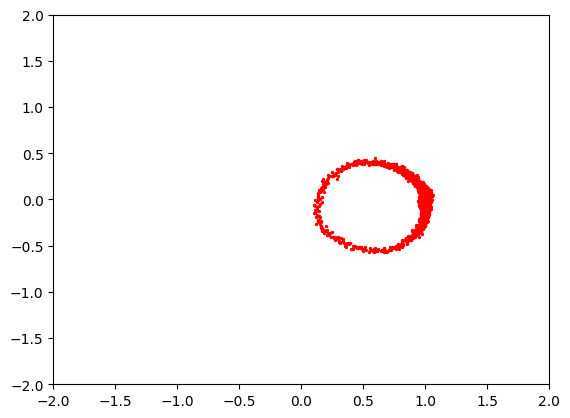

In [66]:

#x= np.linspace(0,1.0,101)
#y_pred = [mag_slope *xi + mag_intercept for xi in x]
plt.scatter(sd_preprocessed.real, sd_preprocessed.imag, color='r', s=2)
plt.plot(0,0,color='r')
#plt.plot(x,y_pred )
#plt.scatter(0,0, color='black')
plt.xlim(-2,2)
plt.ylim(-2,2)


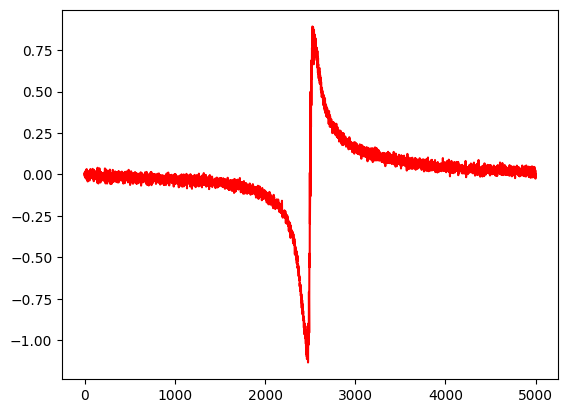

In [20]:
plt.plot(np.angle(sd_preprocessed), color='r')

# Remove remaining delay

Q_guess: 11894.254295532646
-3.665328059911756e-10
phi (preprocessing): 2.8443495190417085


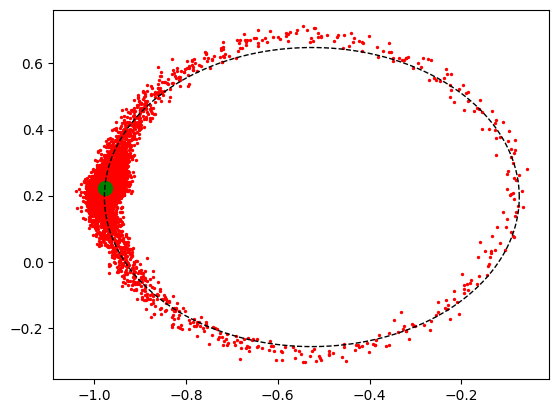

In [76]:
# NOT WORKING
res.fitter.delay_guess = 0 #if none 
delay = res.fitter.find_delay(fd, sd_preprocessed ) #not working
print(delay)
sd_delay_removed = remove_delay(fd, sd_preprocessed,delay)
t = np.linspace(0, 2*np.pi, 512)
xc, yc, r = find_circle(sd_delay_removed.real, sd_delay_removed.imag)
plt.plot(xc + r*np.cos(t), yc + r*np.sin(t), 'k--', lw=1, label='circle fit')



plt.scatter(sd_delay_removed.real,sd_delay_removed.imag, color='r', s=2)

ORP = res.fitter.find_off_res_point(fd,sd_delay_removed)
plt.scatter(ORP.real,ORP.imag,color='g',s=100)
plt.autoscale(True)


# Preprocess circle

anchor_to_point

 Rotates and scales the scattering data to send the off-resonant point(**ORP**) to an anchor point (e.g. 1+0*1j).

In [25]:
res.fitter.theta_0

-0.05922190144689941

In [62]:
print(res.fitter.theta_0)

sd_rotated = res.fitter.anchor_to_point(fd,sd_delay_removed)



-0.05922190144689941
phi (preprocessing): 2.8443495190417085


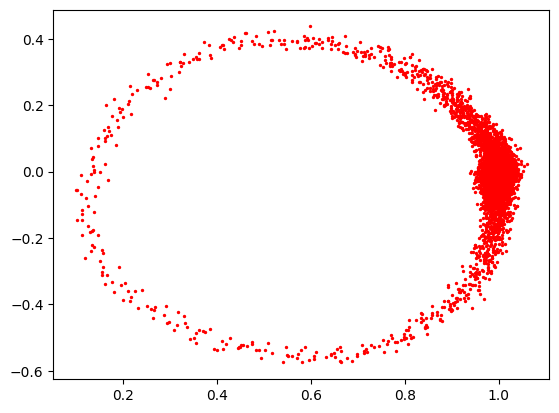

In [64]:
plt.scatter(sd_rotated.real,sd_rotated.imag,color='r', s=2)
plt.xlim(0,2)
plt.ylim(-1,1)
plt.autoscale(True)


phi (preprocessing): 3.087265592846405


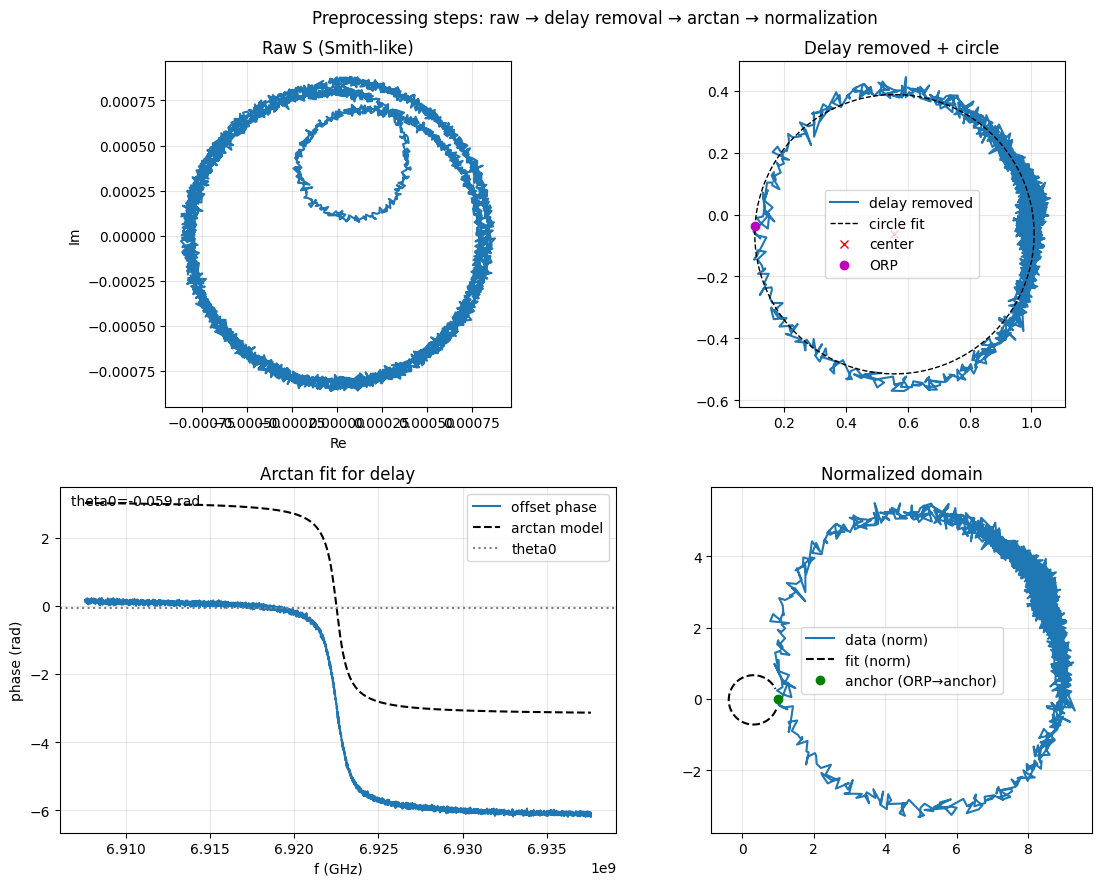

In [46]:
z2 =sd_preprocessed
xc, yc, r = find_circle(np.real(z2), np.imag(z2))
t = np.linspace(0, 2*np.pi, 512)
# Offset phase vs arctan model
theta0 = res.fitter.theta_0 if res.fitter.theta_0 is not None else 0.0
Ql_g  = res.fitter.Ql_guess if res.fitter.Ql_guess is not None else (params['Q'].value if 'Q' in params else 0.0)
fr_g  = res.fitter.fr_guess if res.fitter.fr_guess is not None else (params['f0'].value if 'f0' in params else fd[np.argmax(np.abs(np.gradient(z2, fd)))])

off_phase = np.unwrap(np.angle(z2 - (xc + 1j*yc)))
atan_phase = theta0 + 2*np.arctan(2*Ql_g*(1 - fd/fr_g))

# ORP and normalization
orp = res.fitter.find_off_res_point(fd, z2)
anchor = res.fitter.off_res_point
z2_norm = anchor * z2 / orp

# Model in normalized domain
method_obj = res.fitter.fit_method
if hasattr(method_obj, 'fit_function'):
    s_fit_n = method_obj.fit_function(fd, params)
else:
    kw = {}
    for k in ['Q', 'Qc', 'f0', 'phi']:
        if k in params:
            kw[k] = params[k].value
    s_fit_n = method_obj.func(fd, **kw)

# Figure
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
# (1) Raw Smith
axs[0,0].plot(np.real(sd_raw), np.imag(sd_raw), label='raw')
axs[0,0].set_aspect('equal', adjustable='box')
axs[0,0].set_title('Raw S (Smith-like)')
axs[0,0].set_xlabel('Re')
axs[0,0].set_ylabel('Im')
axs[0,0].grid(True, alpha=0.3)
# (2) Delay-removed with circle fit
t = np.linspace(0, 2*np.pi, 512)
axs[0,1].plot(np.real(z2), np.imag(z2), label='delay removed')
axs[0,1].plot(xc + r*np.cos(t), yc + r*np.sin(t), 'k--', lw=1, label='circle fit')
axs[0,1].plot([xc], [yc], 'rx', label='center')
# Mark ORP on the delay-removed circle
axs[0,1].plot([np.real(orp)], [np.imag(orp)], 'mo', label='ORP')
axs[0,1].set_aspect('equal', adjustable='box')
axs[0,1].set_title('Delay removed + circle')
axs[0,1].legend()
axs[0,1].grid(True, alpha=0.3)
# (3) Offset phase vs arctan model
axs[1,0].plot(fd, off_phase, label='offset phase')
axs[1,0].plot(fd, atan_phase, 'k--', label='arctan model')
# Show theta0 reference
axs[1,0].axhline(theta0, color='gray', ls=':', label='theta0')
axs[1,0].text(0.02, 0.98, f'theta0={theta0:.3f} rad', transform=axs[1,0].transAxes, va='top')
axs[1,0].set_xlabel('f (GHz)')
axs[1,0].set_ylabel('phase (rad)')
axs[1,0].set_title('Arctan fit for delay')
axs[1,0].legend()
axs[1,0].grid(True, alpha=0.3)
# (4) Normalized Smith with model
axs[1,1].plot(np.real(z2_norm), np.imag(z2_norm), label='data (norm)')
axs[1,1].plot(np.real(s_fit_n), np.imag(s_fit_n), 'k--', label='fit (norm)')
axs[1,1].plot([np.real(anchor)], [np.imag(anchor)], 'go', label='anchor (ORP→anchor)')
axs[1,1].set_aspect('equal', adjustable='box')
axs[1,1].set_title('Normalized domain')
axs[1,1].legend()
axs[1,1].grid(True, alpha=0.3)

fig.suptitle('Preprocessing steps: raw → delay removal → arctan → normalization')
plt.tight_layout()
plt.show()
